# Задача 8. Большой детектор и быстрый поиск ФЭУ

$R = 15$ м, $N = 2000$, $r = 10$ см, $a = 0.5$. ФЭУ расставлены, как в задаче 1, по спирали Фибоначчи.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from detector import Detector, fibonacci_sphere
from source import Source

det = Detector(R=15.0, N=2000, r=0.10, a=0.5, rng=8)
print(det.pmt_positions.shape)
print(f"мин. расстояние между ФЭУ: {det.min_pmt_distance():.3f} м")
print(f"покрытие: {det.coverage():.4%}")

(2000, 3)
мин. расстояние между ФЭУ: 1.037 м
покрытие: 2.2222%


расстояние до ближайшего соседа: 1.137 ± 0.015 м (идеальная гексагональная решётка: 1.278 м)


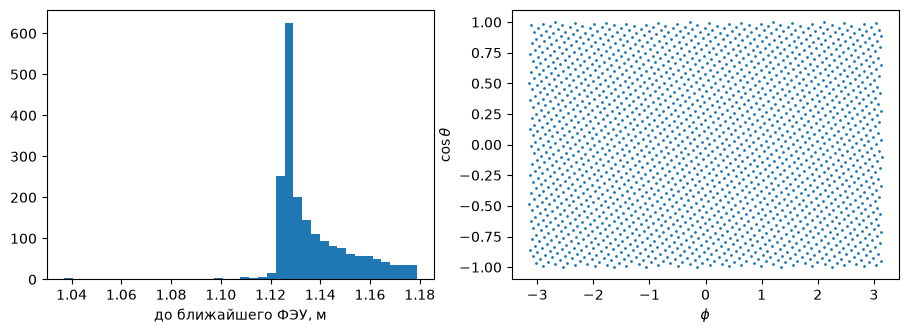

In [2]:
d = np.linalg.norm(det.pmt_positions[:, None] - det.pmt_positions[None], axis=2)
np.fill_diagonal(d, np.inf)
nearest = d.min(axis=1)
print(f"расстояние до ближайшего соседа: {nearest.mean():.3f} ± {nearest.std():.3f} м "
      f"(идеальная гексагональная решётка: {np.sqrt(8*np.pi/np.sqrt(3)/det.N)*det.R:.3f} м)")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(nearest, bins=40); ax[0].set_xlabel('до ближайшего ФЭУ, м')
th = np.arccos(det.pmt_directions[:, 2]); ph = np.arctan2(det.pmt_directions[:, 1], det.pmt_directions[:, 0])
ax[1].scatter(ph, np.cos(th), s=1); ax[1].set_xlabel(r'$\phi$'); ax[1].set_ylabel(r'$\cos\theta$')
plt.show()

In [3]:
import k3d
plot = k3d.plot()
plot += k3d.points(det.pmt_positions.astype(np.float32), point_size=0.5, color=0xff8800)
plot.display()

Output()

## Оптимизация поиска ФЭУ

**Перебор (`brute`)**, как в задаче 1: для каждой точки проверяются все $N$ катодов — матрица $(M, N)$, сложность $O(MN)$. При $N = 2000$ и $10^5$ фотонов это $2\cdot10^8$ проверок и ~3 ГБ промежуточных массивов.

**Сетка (`grid`)** — собственный алгоритм. Поверхность делится на ячейки по $(\cos\theta, \phi)$; шаг по $\cos\theta$ равный, поэтому ячейки равны по площади. Один раз при построении для каждой ячейки запоминается короткий список ФЭУ-кандидатов — тех, чей катод может задевать ячейку: угловое расстояние от центра ячейки до оси ФЭУ не больше $\alpha$ + полуразмер ячейки ($\sin\alpha = r/R$). Списки дополняются $-1$ до общей длины $K$ и хранятся в массиве `(n_cells, K)`. Для точки номер ячейки вычисляется за $O(1)$ арифметикой, а проверяются только её $K \ll N$ кандидатов: сложность $O(MK)$.

**k-d дерево (`kdtree`, scipy)**: ближайший к точке центр ФЭУ за $O(\log N)$, затем одна проверка катода. Это корректно, потому что катоды не перекрываются: если точка на катоде $k$, угловое расстояние до его оси $<\alpha$, а до любой другой оси $> \alpha$, т.е. $k$ — ближайший.

Все три метода дают одинаковый результат — проверено тестом `test_fast_search_matches_brute`, в том числе на точках в пределах ±2% от края катода.

сетка 31 × 62 = 1922 ячеек, K = 37, кандидатов в ячейке в среднем 4.5


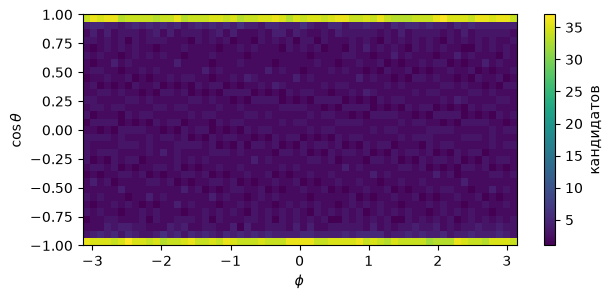

In [4]:
g = det.build_grid()
n_cand = (g['table'] >= 0).sum(axis=1)
print(f"сетка {g['n_cos']} × {g['n_phi']} = {g['table'].shape[0]} ячеек, K = {g['table'].shape[1]}, "
      f"кандидатов в ячейке в среднем {n_cand.mean():.1f}")
plt.figure(figsize=(7, 3))
plt.imshow(n_cand.reshape(g['n_cos'], g['n_phi']), aspect='auto', origin='lower',
           extent=[-np.pi, np.pi, -1, 1])
plt.colorbar(label='кандидатов'); plt.xlabel(r'$\phi$'); plt.ylabel(r'$\cos\theta$'); plt.show()

## Скорость

In [5]:
rng = np.random.default_rng(0)
def random_points(M):
    v = rng.normal(size=(M, 3))
    return det.R * v / np.linalg.norm(v, axis=1, keepdims=True)

def timeit(f, repeat=3):
    best = np.inf
    for _ in range(repeat):
        t = time.perf_counter(); f(); best = min(best, time.perf_counter() - t)
    return best

pts = random_points(20_000)
ref = det.pmt_index_brute(pts)
for name in ('brute', 'grid', 'kdtree'):
    f = getattr(det, f'pmt_index_{name}')
    assert np.array_equal(f(pts), ref)
    print(f"{name:7s}: {timeit(lambda: f(pts))*1e3:8.2f} мс на 20 000 точек")

brute  :   235.79 мс на 20 000 точек
grid   :    40.55 мс на 20 000 точек


kdtree :    10.38 мс на 20 000 точек


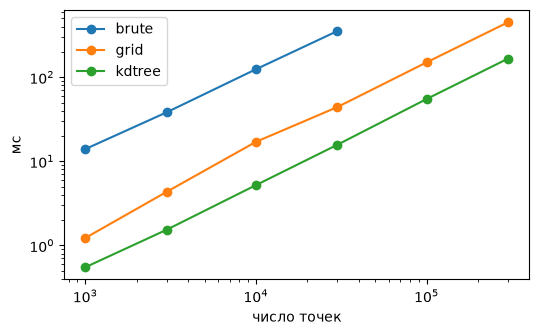

In [6]:
sizes = [1_000, 3_000, 10_000, 30_000, 100_000, 300_000]
res = {m: [] for m in ('brute', 'grid', 'kdtree')}
for M_ in sizes:
    p = random_points(M_)
    for m in res:
        if m == 'brute' and M_ > 30_000:
            res[m].append(np.nan); continue
        res[m].append(timeit(lambda: getattr(det, f'pmt_index_{m}')(p)))
plt.figure(figsize=(6, 3.5))
for m, t in res.items():
    plt.loglog(sizes, np.array(t) * 1e3, 'o-', label=m)
plt.xlabel('число точек'); plt.ylabel('мс'); plt.legend(); plt.show()

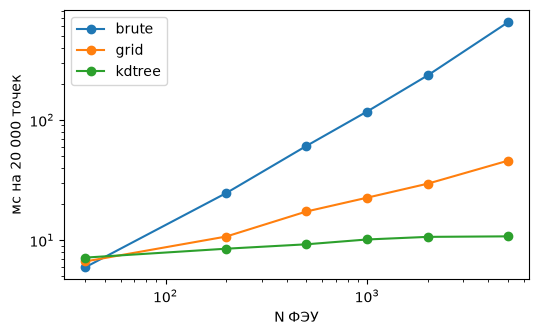

brute    5.96   24.66   60.85  117.64  235.29  650.04
grid    6.66   10.73   17.33   22.58   29.54   45.88
kdtree    7.17    8.50    9.25   10.14   10.66   10.77


In [7]:
Ns = [40, 200, 500, 1000, 2000, 5000]
resN = {m: [] for m in ('brute', 'grid', 'kdtree')}
p0 = rng.normal(size=(20_000, 3)); p0 /= np.linalg.norm(p0, axis=1, keepdims=True)
for N_ in Ns:
    d_ = Detector(R=15.0, N=N_, r=0.10)
    d_.build_grid(); d_.pmt_index_kdtree(p0[:1] * d_.R)   # построение индексов вне замера
    for m in resN:
        resN[m].append(timeit(lambda: getattr(d_, f'pmt_index_{m}')(p0 * d_.R)))
plt.figure(figsize=(6, 3.5))
for m, t in resN.items():
    plt.loglog(Ns, np.array(t) * 1e3, 'o-', label=m)
plt.xlabel('N ФЭУ'); plt.ylabel('мс на 20 000 точек'); plt.legend(); plt.show()
for m, t in resN.items():
    print(m, ' '.join(f'{x*1e3:7.2f}' for x in t))

## Событие 1 МэВ в центре большого детектора

<Q> = 110.82 ± 0.40,  ожидание a*Y*coverage = 111.11


brute  :  125.14 мс / событие
grid   :   15.63 мс / событие
kdtree :    6.12 мс / событие


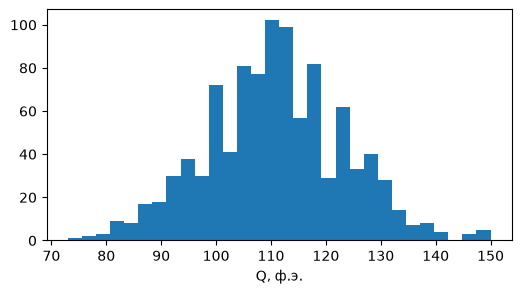

In [8]:
src = Source(Y=10_000, rng=8)
det.search = 'grid'
Qs = np.array([det.response(np.zeros(3), src.directions(1.0)).sum() for _ in range(1000)])
print(f"<Q> = {Qs.mean():.2f} ± {Qs.std()/np.sqrt(len(Qs)):.2f},  ожидание a*Y*coverage = {det.a*src.Y*det.coverage():.2f}")
t = {}
for m in ('brute', 'grid', 'kdtree'):
    det.search = m
    t[m] = timeit(lambda: det.response(np.zeros(3), src.directions(1.0)), 5)
    print(f"{m:7s}: {t[m]*1e3:7.2f} мс / событие")
plt.figure(figsize=(6, 3)); plt.hist(Qs, bins=30); plt.xlabel('Q, ф.э.'); plt.show()

**Выводы.**
- ФЭУ расставлены равномерно: расстояние до ближайшего соседа 1.14 ± 0.015 м (разброс ~1%), покрытие 2.2%. Заряд события 1 МэВ в центре 110.8 ± 0.4 ф.э. при ожидании $aY\cdot$покрытие = 111.1.
- При $N = 2000$ поиск по сетке быстрее перебора в ≈6 раз, k-d дерево — в ≈23 раза (20 000 точек). Событие целиком: 125 мс → 16 мс (сетка) → 6 мс (дерево).
- Время перебора растёт линейно с $N$, время сетки — гораздо медленнее (вклад построения таблицы и длины $K$), время дерева почти не зависит от $N$ ($O(\log N)$). При $N = 40$ все методы одинаковы — оптимизация нужна именно для больших детекторов.
- Слабое место сетки — полюса: ячейки по $\phi$ там узкие клинья, и в одну ячейку попадает до $K = 37$ кандидатов при среднем 4.5. Поскольку список дополняется до общей длины $K$, проверяется 37 кандидатов для каждой точки. Улучшение: делать число ячеек по $\phi$ в каждом поясе пропорциональным $\sin\theta$ (ячейки близкой формы) — тогда $K$ станет ~5–10 и сетка приблизится к дереву.